# 9. Jakość i niepewność wyników algorytmów dla zbioru Original

Notebook ponownie oblicza metryki pięciu aktywnych algorytmów na wydzielonych zbiorach testowych Original dla wariantów `full` i `optimized`. Raportuje 95% przedziały bootstrap oraz zmianę po redukcji cech.

Nie istnieje niezależny zbiór zewnętrzny zgodny ze schematem 111/74 cech. Wyników nie wolno interpretować jako dowodu generalizacji na nowe domeny. Brak ten jest jawnie zapisany jako ograniczenie badania.


In [1]:
import importlib
import os
import sys
from pathlib import Path


def locate_backend_root():
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        nested_backend = candidate / 'backend'
        if (candidate / 'config').is_dir() and (candidate / 'notebooks').is_dir():
            return candidate
        if (nested_backend / 'config').is_dir() and (nested_backend / 'notebooks').is_dir():
            return nested_backend
    raise FileNotFoundError('Nie znaleziono katalogu backend')


backend_root = locate_backend_root()
notebooks_dir = backend_root / 'notebooks' / 'original'
os.chdir(notebooks_dir)
sys.path.insert(0, str(backend_root))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/phishing-detector-matplotlib')
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])
print(f'Backend: {backend_root}')


Backend: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend


In [2]:
import json

import pandas as pd

from config.project_paths import RESULTS_ROOT
from services.model_repository import ModelRepository
from utils.benchmark_plots import plot_heldout_results
from utils.research_benchmark import (
    binary_metrics,
    classifier_probabilities,
    prediction_checksum,
    stratified_bootstrap,
    validate_active_payload,
)

RANDOM_STATE = 42
BOOTSTRAP_REPETITIONS = 1000
ALGORITHMS = ('logistic_regression', 'random_forest', 'xgboost', 'svm', 'mlp')
MODES = ('full', 'optimized')
METRICS = ('accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'false_positive_rate', 'specificity')
MODEL_LABELS = {
    'logistic_regression': 'Regresja Logistyczna',
    'random_forest': 'Random Forest',
    'xgboost': 'XGBoost',
    'svm': 'SVM',
    'mlp': 'MLP',
}
MODEL_ROOT = backend_root / 'models'
DATA_ROOT = backend_root / 'data' / 'test'
OUTPUT_DIR = RESULTS_ROOT / 'original' / 'held_out_uncertainty'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Wyniki: {OUTPUT_DIR}')


Wyniki: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/held_out_uncertainty


## Ponowne obliczenie metryk

Każdy artefakt przechodzi walidację schematu i skalera. Predykcje powstają ponownie z aktywnych plików, bez odczytywania historycznego raportu. Bootstrap jest warstwowy względem klasy: 1000 replik, seed 42.


In [3]:
repository = ModelRepository(MODEL_ROOT)
metric_rows = []
interval_rows = []
checksum_rows = []
for mode in MODES:
    frame = pd.read_csv(DATA_ROOT / f'test_dataset_{mode}.csv')
    expected_columns = list(frame.columns.drop('phishing'))
    labels = frame['phishing'].to_numpy(dtype=int)
    for algorithm in ALGORITHMS:
        payload = repository.load(algorithm, mode, 'current')
        validation = validate_active_payload(payload, expected_columns, algorithm)
        values = frame[expected_columns]
        scaler = payload.get('scaler')
        values = scaler.transform(values) if scaler is not None else values
        probabilities = classifier_probabilities(payload['model'], values)
        threshold = validation['threshold']
        metrics = binary_metrics(labels, probabilities, threshold)
        metric_rows.append({
            'algorithm': algorithm,
            'mode': mode,
            'rows': len(frame),
            'threshold': threshold,
            **metrics,
        })
        intervals = stratified_bootstrap(
            labels, probabilities, threshold, BOOTSTRAP_REPETITIONS, RANDOM_STATE
        )
        interval_rows.extend({
            'algorithm': algorithm,
            'mode': mode,
            'metric': metric,
            'lower_95': bounds[0],
            'upper_95': bounds[1],
            'repetitions': BOOTSTRAP_REPETITIONS,
            'seed': RANDOM_STATE,
        } for metric, bounds in intervals.items())
        checksum_rows.append({
            'algorithm': algorithm,
            'mode': mode,
            'rows': len(frame),
            'prediction_sha256': prediction_checksum(labels, probabilities),
        })
metrics_frame = pd.DataFrame(metric_rows)
intervals_frame = pd.DataFrame(interval_rows)
checksums_frame = pd.DataFrame(checksum_rows)
metrics_frame.to_csv(OUTPUT_DIR / 'held_out_metrics.csv', index=False)
intervals_frame.to_csv(OUTPUT_DIR / 'bootstrap_intervals_95.csv', index=False)
checksums_frame.to_csv(OUTPUT_DIR / 'prediction_checksums.csv', index=False)
display(metrics_frame)


,algorithm,mode,rows,threshold,accuracy,precision,recall,f1,roc_auc,false_positive_rate,specificity
0,logistic_regression,full,40000,0.5,0.945275,0.945832,0.94465,0.945241,0.985027,0.05410,0.94590
1,random_forest,full,40000,0.5,0.980225,0.986920,0.97335,0.980088,0.997218,0.01290,0.98710
2,xgboost,full,40000,0.5,0.971875,0.962147,0.98240,0.972168,0.995362,0.03865,0.96135
3,svm,full,40000,0.5,0.962925,0.969284,0.95615,0.962672,0.991745,0.03030,0.96970
4,mlp,full,40000,0.5,0.964225,0.971701,0.95630,0.963939,0.993921,0.02785,0.97215
5,logistic_regression,optimized,40000,0.5,0.944350,0.944439,0.94425,0.944344,0.985715,0.05555,0.94445
6,random_forest,optimized,40000,0.5,0.979675,0.987598,0.97155,0.979509,0.997241,0.01220,0.98780
7,xgboost,optimized,40000,0.5,0.971900,0.963056,0.98145,0.972166,0.995561,0.03765,0.96235
8,svm,optimized,40000,0.5,0.960550,0.966853,0.95380,0.960282,0.992495,0.03270,0.96730
9,mlp,optimized,40000,0.5,0.964550,0.974176,0.95440,0.964186,0.993986,0.02530,0.97470


## Stabilność po redukcji cech

Różnica `optimized_minus_full` odpowiada zmianie metryki po przejściu z 111 do 74 cech. Dodatnia wartość poprawia metryki jakości, ale dla FPR oznacza więcej fałszywych alarmów.


In [4]:
difference_rows = []
for algorithm, group in metrics_frame.groupby('algorithm'):
    indexed = group.set_index('mode')
    difference_rows.extend({
        'algorithm': algorithm,
        'metric': metric,
        'full': indexed.loc['full', metric],
        'optimized': indexed.loc['optimized', metric],
        'optimized_minus_full': indexed.loc['optimized', metric] - indexed.loc['full', metric],
    } for metric in METRICS)
differences_frame = pd.DataFrame(difference_rows)
differences_frame.to_csv(OUTPUT_DIR / 'optimized_full_differences.csv', index=False)
study_scope = {
    'external_generalization_available': False,
    'reason': 'Brak niezależnego zbioru zewnętrznego zgodnego ze schematem 111/74 cech Original.',
    'valid_interpretation': 'Wydzielony test z tego samego procesu przygotowania danych.',
    'invalid_interpretation': 'Generalizacja na nowe domeny lub nowe źródło danych.',
    'bootstrap_repetitions': BOOTSTRAP_REPETITIONS,
    'bootstrap_seed': RANDOM_STATE,
    'model_source': str(MODEL_ROOT.resolve()),
    'test_source': str(DATA_ROOT.resolve()),
}
(OUTPUT_DIR / 'study_scope.json').write_text(
    json.dumps(study_scope, ensure_ascii=False, indent=2) + '\n',
    encoding='utf-8',
)
display(differences_frame)


,algorithm,metric,full,optimized,optimized_minus_full
0,logistic_regression,accuracy,0.945275,0.944350,-0.000925
1,logistic_regression,precision,0.945832,0.944439,-0.001393
2,logistic_regression,recall,0.944650,0.944250,-0.000400
3,logistic_regression,f1,0.945241,0.944344,-0.000896
4,logistic_regression,roc_auc,0.985027,0.985715,0.000688
5,logistic_regression,false_positive_rate,0.054100,0.055550,0.001450
6,logistic_regression,specificity,0.945900,0.944450,-0.001450
7,mlp,accuracy,0.964225,0.964550,0.000325
8,mlp,precision,0.971701,0.974176,0.002474
9,mlp,recall,0.956300,0.954400,-0.001900


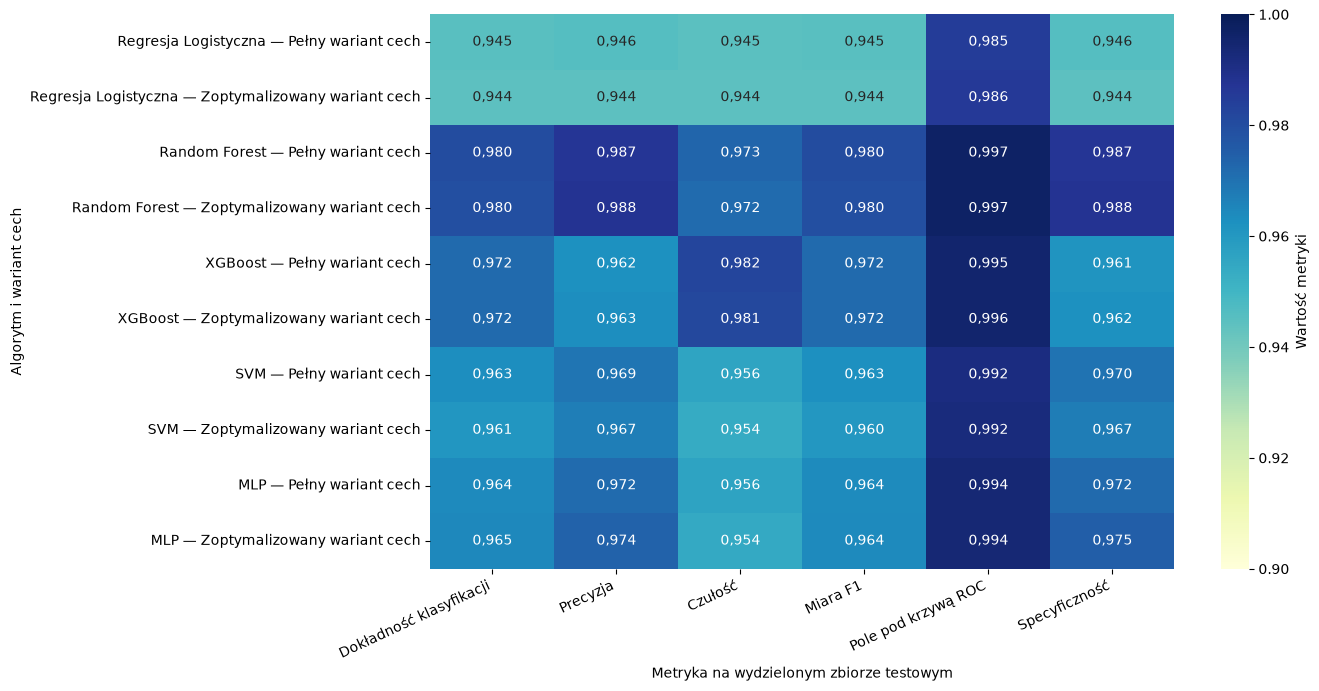

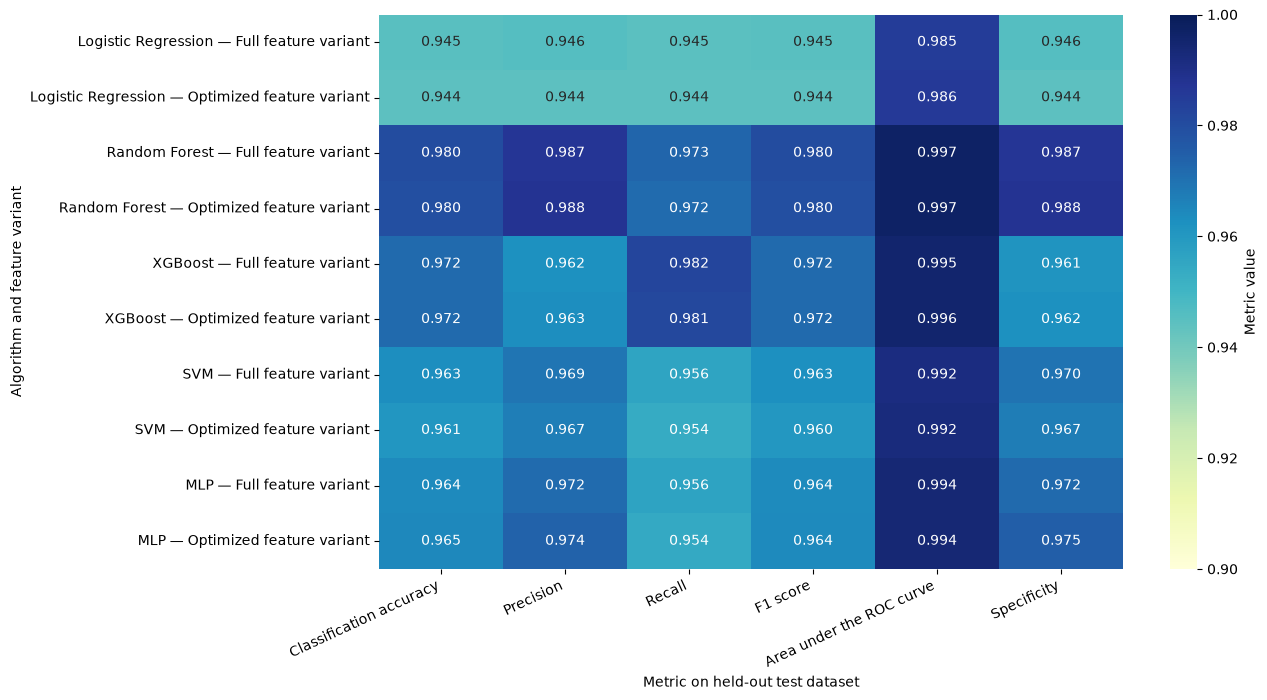

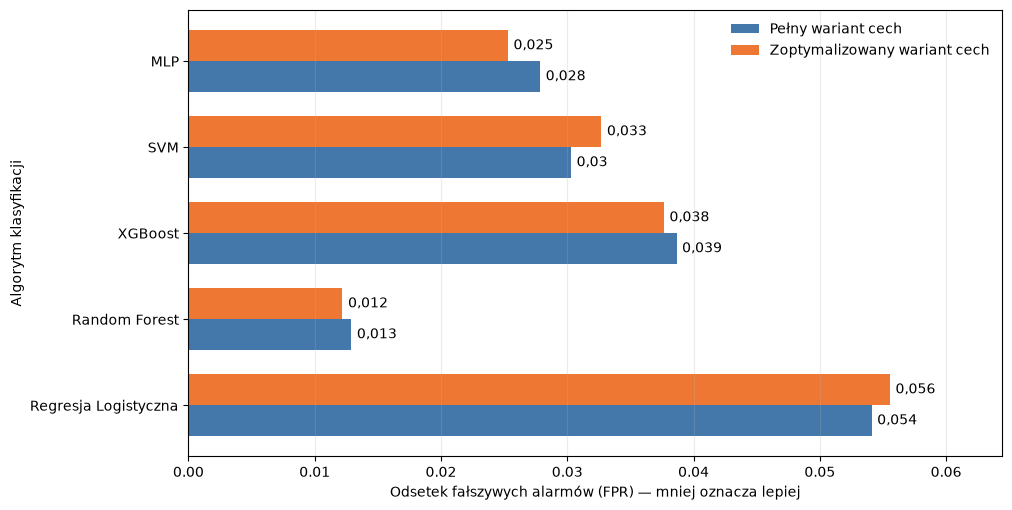

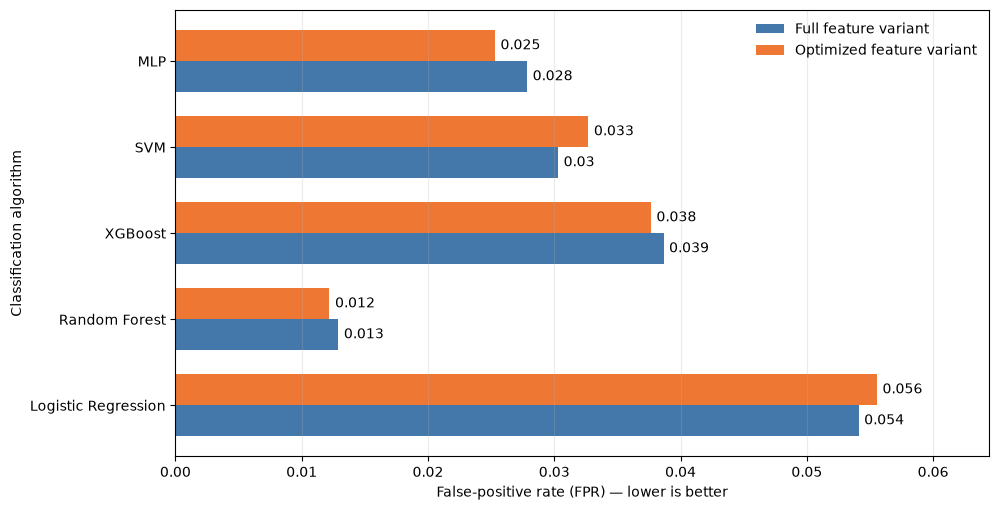

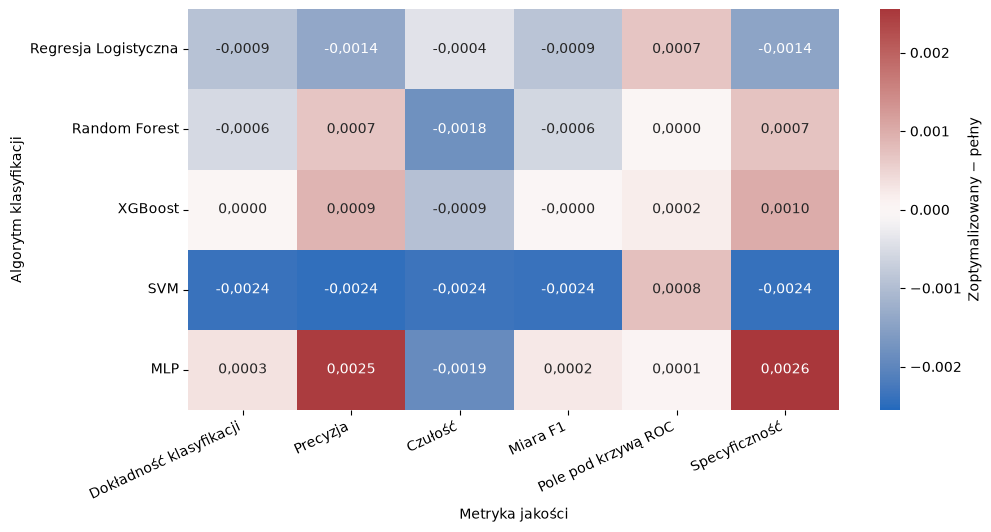

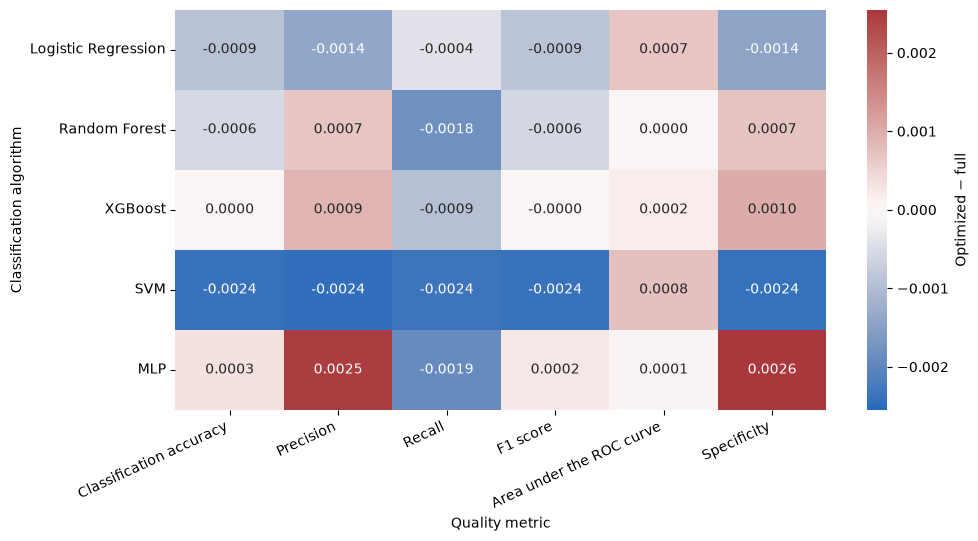

In [1]:
plot_heldout_results(metrics_frame, differences_frame, OUTPUT_DIR, MODEL_LABELS)


## Interpretacja

- heatmapa podaje wartości bezpośrednio i oddziela warianty cech;
- wykres FPR używa zasady „mniej oznacza lepiej”, więc nie należy oceniać go jak accuracy lub F1;
- rozbieżna heatmapa zmian pokazuje kierunek i skalę wpływu redukcji cech;
- przedziały bootstrap opisują niepewność próbkowania rekordów przy stałym algorytmie i progu;
- badanie nie obejmuje niepewności ponownego uczenia ani generalizacji zewnętrznej;
- ranking Original pozostaje oddzielony od URL Corpus.


In [6]:
best = metrics_frame.sort_values(
    ['f1', 'false_positive_rate'], ascending=[False, True]
).iloc[0]
print(
    f"Najwyższe F1: {MODEL_LABELS[best['algorithm']]} ({best['mode']}), "
    f"F1={best['f1']:.4f}, FPR={best['false_positive_rate']:.4f}."
)
print('Generalizacja zewnętrzna Original: niedostępna z powodu braku zgodnego zbioru.')


Najwyższe F1: Random Forest (full), F1=0.9801, FPR=0.0129.
Generalizacja zewnętrzna Original: niedostępna z powodu braku zgodnego zbioru.
